Note: This notebook was originally executed in a Kaggle environment. The dataset consists of 3,256 PBS images and is too large for GitHub. To run this locally, download the dataset from [https://www.kaggle.com/datasets/mehradaria/leukemia]and update the ../input/leukemia/ file paths to your local directory.

**Acute Lymphoblastic Leukemia(ALL) Classification Using EfficientNetB3**

**Importing Modules**

In [1]:
import os
import pandas as pd
from fastai.vision.all import *
from fastai.vision import models
from fastai.metrics import error_rate, accuracy



import warnings
warnings.filterwarnings("ignore")
set_seed(42)

**Data Preprocessing (Reading Dataset and Making DataFrames)**

In [2]:
# Define data directory
data_dir = '../input/leukemia/Original'

# Generate data paths with labels
filepaths = []
labels = []

folds = os.listdir(data_dir)
for fold in folds:
    foldpath = os.path.join(data_dir, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)
        filepaths.append(fpath)
        labels.append(fold)

# Concatenate data paths with labels into one dataframe
Fseries = pd.Series(filepaths, name='filepaths')
Lseries = pd.Series(labels, name='labels')
df = pd.concat([Fseries, Lseries], axis=1)




In [3]:
df

,filepaths,labels
0,../input/leukemia/Original/Pro/WBC-Malignant-Pro-722.jpg,Pro
1,../input/leukemia/Original/Pro/WBC-Malignant-Pro-537.jpg,Pro
2,../input/leukemia/Original/Pro/WBC-Malignant-Pro-115.jpg,Pro
3,../input/leukemia/Original/Pro/WBC-Malignant-Pro-777.jpg,Pro
4,../input/leukemia/Original/Pro/WBC-Malignant-Pro-058.jpg,Pro
...,...,...
3251,../input/leukemia/Original/Early/WBC-Malignant-Early-968.jpg,Early
3252,../input/leukemia/Original/Early/WBC-Malignant-Early-558.jpg,Early
3253,../input/leukemia/Original/Early/WBC-Malignant-Early-433.jpg,Early
3254,../input/leukemia/Original/Early/WBC-Malignant-Early-217.jpg,Early


In [4]:
# Data augmentation and image data loaders
dls = ImageDataLoaders.from_df(df,
                                fn_col=0,  # filepaths
                                label_col=1,  # labels
                                valid_pct=0.2,
                                folder='',
                                item_tfms=Resize(224),
                                batch_tfms=[*aug_transforms(size=224), Normalize.from_stats(*imagenet_stats)])




In [ ]:
dls.show_batch(max_n=16)

**Creating Model for Classification**

SuggestedLRs(valley=0.0014454397605732083)

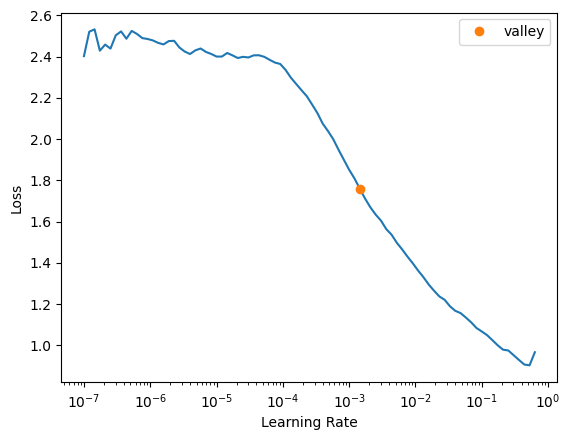

In [6]:
# Model training
learn = cnn_learner(dls, 'efficientnet_b3', metrics=[accuracy, error_rate]).to_fp16()
learn.lr_find()

In [7]:
# Fine-tune the model using the one-cycle policy
learn.fit_one_cycle(20, lr_max=slice(1e-2, 1e-1))

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.462926,0.125472,0.958525,0.041475,00:14
1,0.319664,0.547739,0.933948,0.066052,00:13
2,0.359747,0.539330,0.958525,0.041475,00:13
3,0.526988,2.760422,0.894009,0.105991,00:13
4,0.653758,3.268379,0.863287,0.136713,00:13
5,0.771698,nan,0.970814,0.029186,00:13
6,0.585546,nan,0.989247,0.010753,00:13
7,0.713169,nan,0.984639,0.015361,00:14
8,0.497468,nan,0.989247,0.010753,00:13
9,0.395051,nan,0.970814,0.029186,00:13


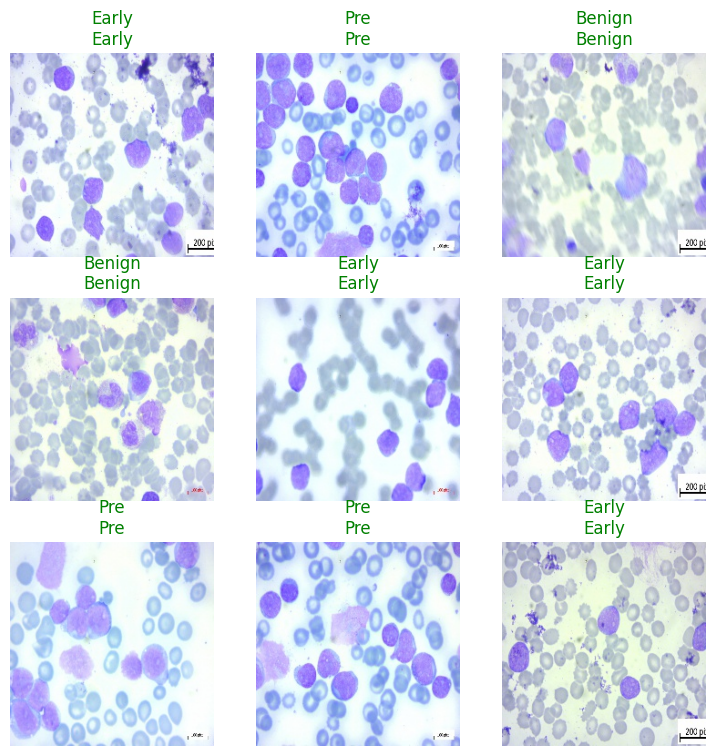

In [8]:
learn.show_results()

In [9]:
# Save the trained model
learn.export('/kaggle/working/leukemia_model.pkl')

**Model Interpretation**

[]

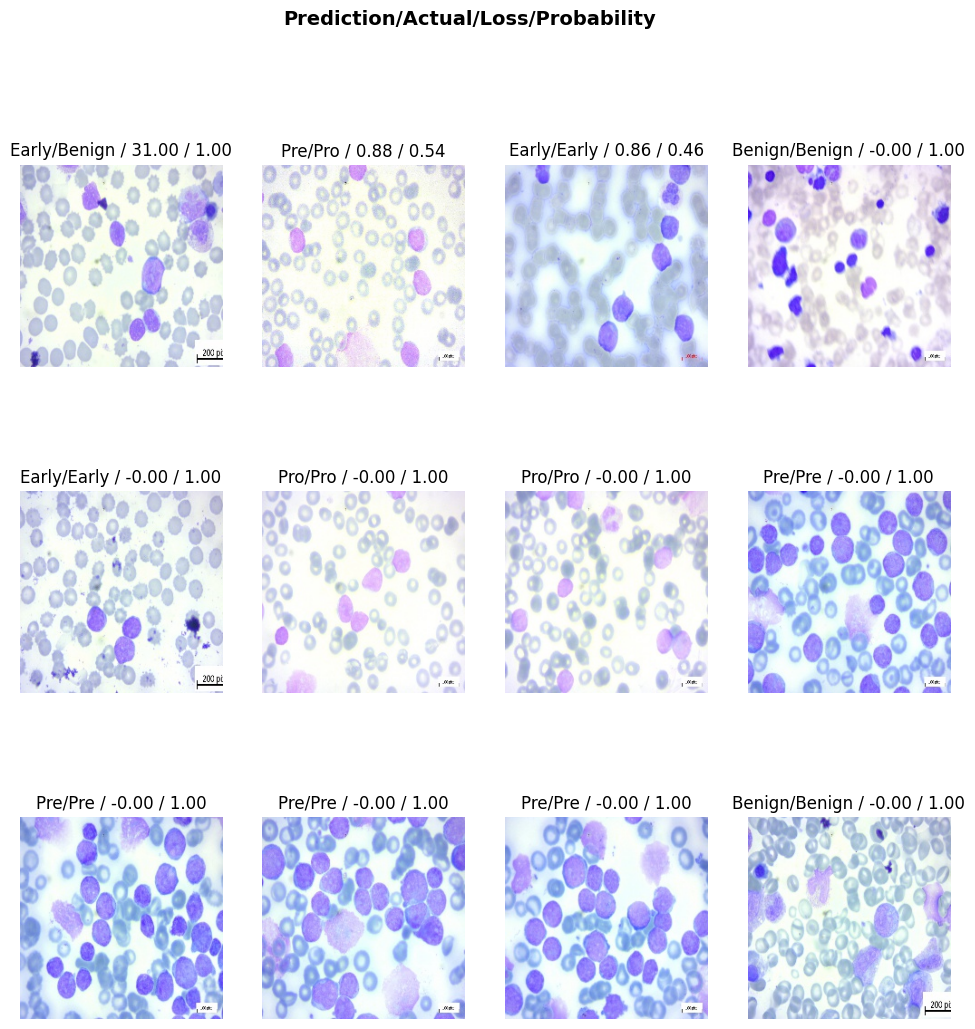

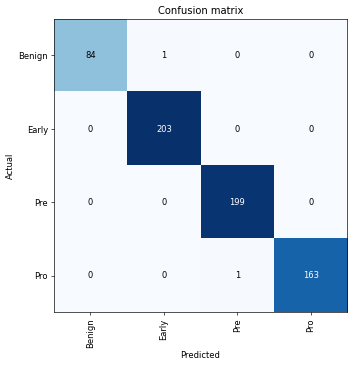

In [10]:
# Model interpretation
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_top_losses(12, figsize=(12, 12))
interp.plot_confusion_matrix(figsize=(6, 6), dpi=60)
interp.most_confused(min_val=2)
